**Pre-requisites for polars to work with PostgreSQL:**

- pip install connectorx or pip install adbc-driver-postgresql
- pip install pyarrow

**NOTE:** ConnectorX is the default engine.  If using ADBC driver, then add `engine="adbc"` to the `read_database_*()` method.  
[REFERENCE](https://docs.pola.rs/user-guide/io/database/)

**Pre-requisites for working with Altair:**

- pip install altair

**Pre-requisites for working with Plotly:**

- pip install plotly (within your kernel AND within the virtual environment that jupyterlab is running in)

In [1]:
from dotenv import load_dotenv
from urllib.parse import quote_plus  # If your password has special characters like #, @, :, /, ?, or %, then need to encode them with %/percent encoding
import os
import polars as pl

In [2]:
load_dotenv()  # laod credentials from a .env file

True

In [3]:
DB_NAME=os.getenv("DB_NAME")
DB_USER=os.getenv("DB_USER")
DB_PASSWORD=quote_plus(os.getenv("DB_PASSWORD"))
DB_HOST=os.getenv("DB_HOST")
DB_PORT=os.getenv("DB_PORT")

In [4]:
uri = f"postgresql://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/us_population"

In [5]:
query = "SELECT * FROM public.us_counties_pop_est_2020_2025"

df = pl.read_database_uri(query=query, uri=uri)

In [6]:
df.head()

sumlev,region,division,state,county,stname,ctyname,estimatesbase2020,popestimate2020,popestimate2021,popestimate2022,popestimate2023,popestimate2024,popestimate2025,npopchg2020,npopchg2021,npopchg2022,npopchg2023,npopchg2024,npopchg2025,births2020,births2021,births2022,births2023,births2024,births2025,deaths2020,deaths2021,deaths2022,deaths2023,deaths2024,deaths2025,naturalchg2020,naturalchg2021,naturalchg2022,naturalchg2023,naturalchg2024,…,gqestimatesbase2020,gqestimates2020,gqestimates2021,gqestimates2022,gqestimates2023,gqestimates2024,gqestimates2025,rbirth2021,rbirth2022,rbirth2023,rbirth2024,rbirth2025,rdeath2021,rdeath2022,rdeath2023,rdeath2024,rdeath2025,rnaturalchg2021,rnaturalchg2022,rnaturalchg2023,rnaturalchg2024,rnaturalchg2025,rinternationalmig2021,rinternationalmig2022,rinternationalmig2023,rinternationalmig2024,rinternationalmig2025,rdomesticmig2021,rdomesticmig2022,rdomesticmig2023,rdomesticmig2024,rdomesticmig2025,rnetmig2021,rnetmig2022,rnetmig2023,rnetmig2024,rnetmig2025
str,str,str,str,str,str,str,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,…,i32,i32,i32,i32,i32,i32,i32,"decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]","decimal[38,10]"
"""040""","""3""","""6""","""01""","""000""","""Alabama""","""Alabama""",5025437,5032962,5050058,5076868,5117850,5163055,5193088,7525,17096,26810,40982,45205,30033,13899,57327,58251,58640,57648,57680,15121,69137,67263,60111,59508,59868,-1222,-11810,-9012,-1471,-1860,…,129053,132345,132684,139735,142803,145212,145596,11.3709979800,11.5041820200,11.5039964800,11.2145769300,11.1392822600,13.7135501100,13.2839916100,11.7925772900,11.5764127800,11.5618334000,-2.3425521300,-1.7798095900,-0.2885808100,-0.3618358500,-0.4225511400,0.3586227100,1.6571662500,2.4759880600,4.2996214800,1.7276702300,5.1165226300,5.4741192000,5.8410639700,4.8542419200,4.5109458200,5.4751453400,7.1312854500,8.3170520300,9.1538634000,6.2386160600
"""050""","""3""","""6""","""01""","""001""","""Alabama""","""Autauga County""",58805,58914,59207,59755,60502,61476,61920,109,293,548,747,974,444,165,702,732,725,727,730,177,700,710,570,604,599,-12,2,22,155,123,…,484,484,459,467,484,502,489,11.8861167800,12.3064508000,12.0575101700,11.9201823300,11.8318259900,11.8522532000,11.9365847900,9.4796976500,9.9034252100,9.7085805100,0.0338635800,0.3698660100,2.5778125200,2.0167571200,2.1232454900,0.2539768500,0.6892957400,1.6963669500,2.2135139100,1.0697267300,3.6911302800,8.5909786300,8.1824758600,11.7562183300,3.9709553000,3.9451071400,9.2802743700,9.8788428100,13.9697322500,5.0406820300
"""050""","""3""","""6""","""01""","""003""","""Alabama""","""Baldwin County""",231778,233252,239450,246703,254193,261652,267761,1474,6198,7253,7490,7459,6109,558,2327,2449,2622,2467,2477,585,2934,3051,2772,2735,2749,-27,-607,-602,-150,-268,…,3555,3452,3296,3388,3449,3508,3547,9.8455263600,10.0750175400,10.4692391200,9.5648886800,9.3575337200,12.4137405800,12.5516041300,11.0681658500,10.6039604900,10.3850868800,-2.5682142200,-2.4765865900,-0.5989267200,-1.0390718100,-1.0275531600,0.4400235200,2.4354472800,3.6095317200,4.7611201000,1.5262186600,29.7819768100,28.3038467300,26.2769117700,24.8020238600,22.7119470100,30.2220003300,30.7392940100,29.8864434900,29.5631439700,24.2381656700
"""050""","""3""","""6""","""01""","""005""","""Alabama""","""Barbour County""",25225,24958,24510,24744,24681,24520,24607,-267,-448,234,-63,-161,87,59,268,268,275,266,267,93,392,352,320,315,319,-34,-124,-84,-45,-49,…,2718,2475,2223,2697,2701,2661,2788,

## Making Geographic Choropleth Map of U.S. at the County Level

To work with altair visualization library to make county level choropleth map, we need a column called "id" which is just the concatenation of the 2-digit state code and 3-digit county code, but with the leading zero removed.

In [7]:
(
    df
    .with_columns(
        pop_est_2020_2025_diff=pl.col("popestimate2025") - pl.col("popestimate2020"),
        fips=pl.col("state") + pl.col("county"),
    )
    .with_columns(
        perc_change_2020_2025=(pl.col("pop_est_2020_2025_diff") / pl.col("popestimate2020")) * 100,
        id=pl.col("fips").cast(pl.Int64)
    )
    .select(
        pl.col("id"),
        pl.col("state"),
        pl.col("county"),
        pl.col("fips"),
        pl.col("stname"),
        pl.col("ctyname"),
        pl.col("popestimate2020"),
        pl.col("popestimate2025"),
        pl.col("pop_est_2020_2025_diff"),
        pl.col("perc_change_2020_2025")
    )
    .filter(
        (pl.col("county")!="000")
    )
)

id,state,county,fips,stname,ctyname,popestimate2020,popestimate2025,pop_est_2020_2025_diff,perc_change_2020_2025
i64,str,str,str,str,str,i32,i32,i32,f64
1001,"""01""","""001""","""01001""","""Alabama""","""Autauga County""",58914,61920,3006,5.102353
1003,"""01""","""003""","""01003""","""Alabama""","""Baldwin County""",233252,267761,34509,14.794728
1005,"""01""","""005""","""01005""","""Alabama""","""Barbour County""",24958,24607,-351,-1.406363
1007,"""01""","""007""","""01007""","""Alabama""","""Bibb County""",22181,22262,81,0.365177
1009,"""01""","""009""","""01009""","""Alabama""","""Blount County""",59099,60156,1057,1.788524
…,…,…,…,…,…,…,…,…,…
56037,"""56""","""037""","""56037""","""Wyoming""","""Sweetwater County""",42194,41267,-927,-2.196995
56039,"""56""","""039""","""56039""","""Wyoming""","""Teton County""",23381,23333,-48,-0.205295
56041,"""56""","""041""","""56041""","""Wyoming""","""Uinta County""",20462,20728,266,1.299971


In [8]:
df_counties = (
    df
    .with_columns(
        pop_est_2020_2025_diff=pl.col("popestimate2025") - pl.col("popestimate2020"),
        fips=pl.col("state") + pl.col("county"),
    )
    .with_columns(
        perc_change_2020_2025=(pl.col("pop_est_2020_2025_diff") / pl.col("popestimate2020")) * 100,
        id=pl.col("fips").cast(pl.Int64)
    )
    .select(
        pl.col("id"),
        pl.col("state"),
        pl.col("county"),
        pl.col("fips"),
        pl.col("stname"),
        pl.col("ctyname"),
        pl.col("popestimate2020"),
        pl.col("popestimate2025"),
        pl.col("pop_est_2020_2025_diff"),
        pl.col("perc_change_2020_2025")
    )
    .filter(
        (pl.col("county")!="000")
    )
)

In [9]:
import altair as alt
from altair.datasets import data

counties = alt.topo_feature(data.us_10m.url, "counties")

chart = (
    alt.Chart(counties)
    .mark_geoshape()
    .encode(
        color=alt.Color(
            "perc_change_2020_2025:Q",
            title="% change",
            scale=alt.Scale(
                scheme="redblue",
                domain=[-10, 10],
                domainMid=0,
                clamp=True,
                reverse=True   # Want red to be high values, blue to be low values instead
            ),
        ),
        tooltip=[
            alt.Tooltip("ctyname:N", title="County"),
            alt.Tooltip("stname:N", title="State"),
            alt.Tooltip("perc_change_2020_2025:Q", title="% change", format=".1f"),
        ],
    )
    .transform_lookup(
        lookup="id",
        from_=alt.LookupData(
            df_counties,                     # the Polars DataFrame, passed directly
            "id",
            ["perc_change_2020_2025", "ctyname", "stname"],
        ),
    )
    .project(type="albersUsa")
    .properties(width=800, height=500, title="Population change by county, 2020–2025")
)

chart

alt.Chart(...)

## Making Altair Geographic Choropleth Map of U.S. at the State Level

To work with altair visualization library to make *state-level* choropleth map, we need a column called "id" which is just the  2-digit state code.

In [10]:
df_states = (
    df
    .with_columns(
        pop_est_2020_2025_diff=pl.col("popestimate2025") - pl.col("popestimate2020"),
        fips=pl.col("state") + pl.col("county"),
    )
    .with_columns(
        perc_change_2020_2025=(pl.col("pop_est_2020_2025_diff") / pl.col("popestimate2020")) * 100,
        id=pl.col("state").cast(pl.Int64)
    )
    .select(
        pl.col("id"),
        pl.col("state"),
        pl.col("county"),
        pl.col("fips"),
        pl.col("stname"),
        pl.col("ctyname"),
        pl.col("popestimate2020"),
        pl.col("popestimate2025"),
        pl.col("pop_est_2020_2025_diff"),
        pl.col("perc_change_2020_2025")
    )
    .filter(
        (pl.col("county")=="000")
    )
)

In [11]:
df_states

id,state,county,fips,stname,ctyname,popestimate2020,popestimate2025,pop_est_2020_2025_diff,perc_change_2020_2025
i64,str,str,str,str,str,i32,i32,i32,f64
1,"""01""","""000""","""01000""","""Alabama""","""Alabama""",5032962,5193088,160126,3.181546
2,"""02""","""000""","""02000""","""Alaska""","""Alaska""",732906,737270,4364,0.595438
4,"""04""","""000""","""04000""","""Arizona""","""Arizona""",7186647,7623818,437171,6.083101
5,"""05""","""000""","""05000""","""Arkansas""","""Arkansas""",3014399,3114791,100392,3.330415
6,"""06""","""000""","""06000""","""California""","""California""",39527808,39355309,-172499,-0.436399
…,…,…,…,…,…,…,…,…,…
51,"""51""","""000""","""51000""","""Virginia""","""Virginia""",8637303,8880107,242804,2.811109
53,"""53""","""000""","""53000""","""Washington""","""Washington""",7726812,8001020,274208,3.548786
54,"""54""","""000""","""54000""","""West Virginia""","""West Virginia""",1791670,1766147,-25523,-1.424537


In [12]:
import altair as alt
from altair.datasets import data

states = alt.topo_feature(data.us_10m.url, 'states')

chart = (
    alt.Chart(states)
    .mark_geoshape()
    .encode(
        color=alt.Color(
            "perc_change_2020_2025:Q",
            title="% change",
            scale=alt.Scale(
                scheme="redblue",
                domainMid=0,
                reverse=True
            ),
        ),
        tooltip=[
            alt.Tooltip("stname:N", title="State"),
            alt.Tooltip("perc_change_2020_2025:Q", title="% change", format=".1f"),
        ],
    )
    .transform_lookup(
        lookup="id",
        from_=alt.LookupData(
            df_states,                     # the Polars DataFrame, passed directly
            "id",
            ["perc_change_2020_2025", "stname"],
        ),
    )
    .project(type="albersUsa")
    .properties(width=800, height=500, title="Population change by State, 2020–2025")
)

chart

alt.Chart(...)

## Plotly Version at County Level

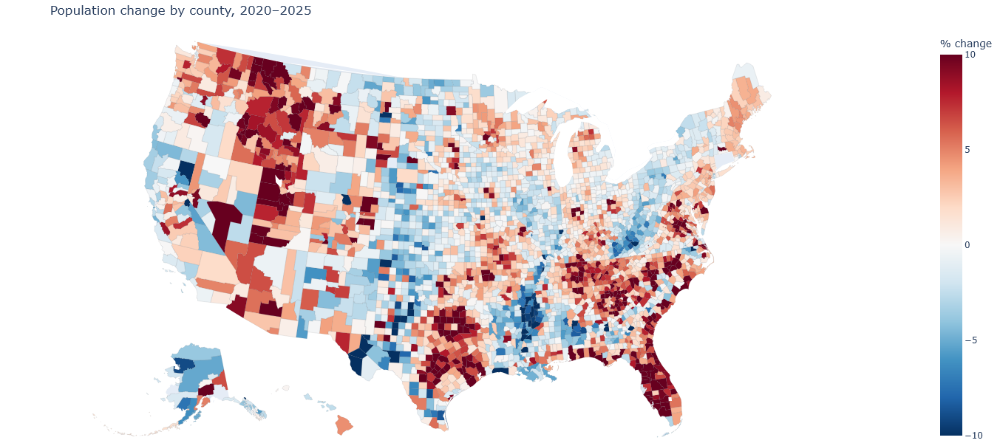

In [13]:
import json
import urllib.request
import plotly.express as px

# County boundaries keyed by 5-digit FIPS
url = "https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json"
with urllib.request.urlopen(url) as f:
    counties = json.load(f)

fig = px.choropleth(
    df_counties,
    geojson=counties,
    # locations="id",
    locations="fips",
    color="perc_change_2020_2025",
    color_continuous_scale="RdBu_r",        # red = decline, blue = growth
    range_color=(-10, 10),                # clip outliers so colors stay readable
    color_continuous_midpoint=0,
    scope="usa",                          # Albers USA projection, AK/HI insets
    hover_name="ctyname",
    hover_data={"stname": True, "id": False, "perc_change_2020_2025": ":.1f"},
    labels={"perc_change_2020_2025": "% change"},
    title="Population change by county, 2020–2025",
)

fig.update_traces(marker_line_width=0.1)   # thin county borders
fig.update_layout(
    margin=dict(l=0, r=0, t=40, b=0),
    width=1200,
    height=600
)
fig.show()

## Plotly Version at State Level

To use Ploty with state level choropleth mapping, we need the 2-character state abbreviation which isn't currently available as a data source.  So we'll have to make one.

In [14]:
state_codes = pl.DataFrame({
    "stname": [
        "Alabama", "Alaska", "Arizona", "Arkansas", "California", "Colorado",
        "Connecticut", "Delaware", "District of Columbia", "Florida", "Georgia",
        "Hawaii", "Idaho", "Illinois", "Indiana", "Iowa", "Kansas", "Kentucky",
        "Louisiana", "Maine", "Maryland", "Massachusetts", "Michigan", "Minnesota",
        "Mississippi", "Missouri", "Montana", "Nebraska", "Nevada", "New Hampshire",
        "New Jersey", "New Mexico", "New York", "North Carolina", "North Dakota",
        "Ohio", "Oklahoma", "Oregon", "Pennsylvania", "Rhode Island", "South Carolina",
        "South Dakota", "Tennessee", "Texas", "Utah", "Vermont", "Virginia",
        "Washington", "West Virginia", "Wisconsin", "Wyoming",
    ],
    "state_abbr": [
        "AL", "AK", "AZ", "AR", "CA", "CO",
        "CT", "DE", "DC", "FL", "GA",
        "HI", "ID", "IL", "IN", "IA", "KS", "KY",
        "LA", "ME", "MD", "MA", "MI", "MN",
        "MS", "MO", "MT", "NE", "NV", "NH",
        "NJ", "NM", "NY", "NC", "ND",
        "OH", "OK", "OR", "PA", "RI", "SC",
        "SD", "TN", "TX", "UT", "VT", "VA",
        "WA", "WV", "WI", "WY",
    ],
})

In [15]:
state_codes

stname,state_abbr
str,str
"""Alabama""","""AL"""
"""Alaska""","""AK"""
"""Arizona""","""AZ"""
"""Arkansas""","""AR"""
"""California""","""CA"""
…,…
"""Virginia""","""VA"""
"""Washington""","""WA"""
"""West Virginia""","""WV"""


Then we need to merge it with our main, state level dataframe that we created earlier:

In [16]:
df_map = (
    df_states
    .join(state_codes, on="stname", how="left")
)

In [17]:
df_map

id,state,county,fips,stname,ctyname,popestimate2020,popestimate2025,pop_est_2020_2025_diff,perc_change_2020_2025,state_abbr
i64,str,str,str,str,str,i32,i32,i32,f64,str
1,"""01""","""000""","""01000""","""Alabama""","""Alabama""",5032962,5193088,160126,3.181546,"""AL"""
2,"""02""","""000""","""02000""","""Alaska""","""Alaska""",732906,737270,4364,0.595438,"""AK"""
4,"""04""","""000""","""04000""","""Arizona""","""Arizona""",7186647,7623818,437171,6.083101,"""AZ"""
5,"""05""","""000""","""05000""","""Arkansas""","""Arkansas""",3014399,3114791,100392,3.330415,"""AR"""
6,"""06""","""000""","""06000""","""California""","""California""",39527808,39355309,-172499,-0.436399,"""CA"""
…,…,…,…,…,…,…,…,…,…,…
51,"""51""","""000""","""51000""","""Virginia""","""Virginia""",8637303,8880107,242804,2.811109,"""VA"""
53,"""53""","""000""","""53000""","""Washington""","""Washington""",7726812,8001020,274208,3.548786,"""WA"""
54,"""54""","""000""","""54000""","""West Virginia""","""West Virginia""",1791670,1766147,-25523,-1.424537,"""WV"""


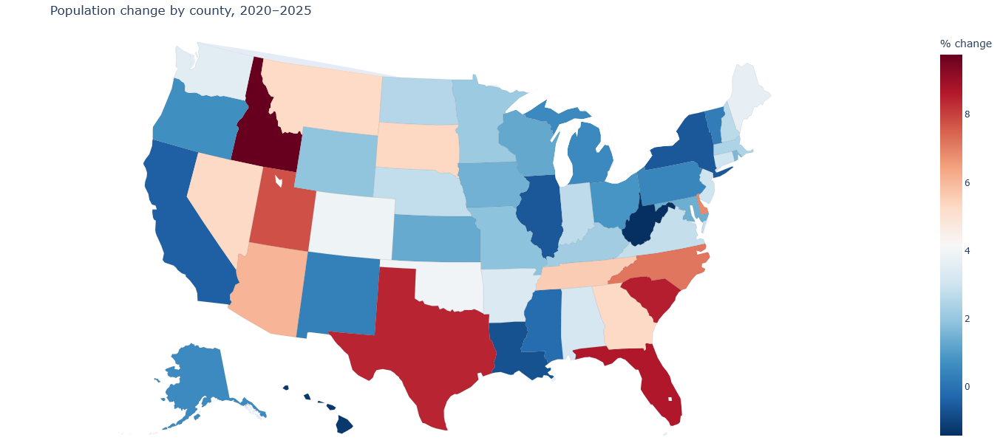

In [18]:
import json
import urllib.request
import plotly.express as px

fig = px.choropleth(
    df_map,
    locations="state_abbr",
    locationmode="USA-states",
    color="perc_change_2020_2025",
    color_continuous_scale="RdBu_r",        # red = decline, blue = growth
    # range_color=(-2, 10),                # clip outliers so colors stay readable
    # color_continuous_midpoint=0,
    scope="usa",                          # Albers USA projection, AK/HI insets
    hover_name="stname",
    hover_data={"perc_change_2020_2025": ":.1f"},
    labels={"perc_change_2020_2025": "% change"},
    title="Population change by county, 2020–2025",
)

fig.update_traces(marker_line_width=0.1)   # thin county borders
fig.update_layout(
    margin=dict(l=0, r=0, t=40, b=0),
    width=1200,
    height=600
)
fig.show()